# Combining analysis and forecasts into one time dimension

DANRA is distributed as separate analysis and forecast datasets.
The analysis is available every 3 hours, while the forecasts provide the hours in between as well as a number of variables that only exist in the forecasts, such as accumulated precipitation.

For many applications it is convenient to have all of this in a single dataset with one hourly `time` dimension.
This notebook shows how to build such a dataset with `xarray`, by combining the analysis with the 3-hourly forecasts.
At the end we also show how the 18-hourly forecasts can be turned into a continuous hourly time series.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

## Loading the data

The DANRA data is split into single level, pressure level and height level datasets, each of which comes as an analysis dataset and two forecast datasets:

- `*_analysis.zarr`: the analysis, every 3 hours, with a `time` dimension.
- `*_forecast_PT3H.zarr`: forecasts started from every analysis (every 3 hours), with lead times of 1 to 3 hours.
- `*_forecast_PT18H.zarr`: forecasts started at 00 UTC and 12 UTC, with lead times of 1 to 18 hours.

We start with the single level analysis and 3-hourly forecasts. As always, the data is loaded lazily, so nothing is downloaded before it is needed.

In [2]:
DANRA_URL = "s3://dmi-danra-061"


def open_danra(name):
    """Open one of the DANRA zarr datasets, e.g. "single_levels_analysis"."""
    return xr.open_zarr(
        f"{DANRA_URL}/{name}.zarr",
        consolidated=True,
        storage_options={
            "anon": True,
        },
    )


ana_sl = open_danra("single_levels_analysis")
fc_sl = open_danra("single_levels_forecast_PT3H")
fc_sl

<xarray.Dataset> Size: 73TB
Dimensions:                   (analysis_time: 97400, forecast_period: 3,
                               y: 589, x: 789)
Coordinates:
  * analysis_time             (analysis_time) datetime64[ns] 779kB 1990-09-01...
  * forecast_period           (forecast_period) timedelta64[ns] 24B 01:00:00 ...
    valid_time                (analysis_time, forecast_period) datetime64[ns] 2MB dask.array<chunksize=(97400, 3), meta=np.ndarray>
  * y                         (y) float64 5kB -6.095e+05 -6.07e+05 ... 8.605e+05
  * x                         (x) float64 6kB -1.999e+06 ... -2.925e+04
    lat                       (y, x) float64 4MB dask.array<chunksize=(295, 263), meta=np.ndarray>
    lon                       (y, x) float64 4MB dask.array<chunksize=(295, 263), meta=np.ndarray>
Data variables: (12/68)
    albedo                    (analysis_time, forecast_period, y, x) float64 1TB dask.array<chunksize=(256, 3, 295, 263), meta=np.ndarray>
    cape_column               (analysis_time, forecast_period, y, x) float64 1TB dask.array<chunksize=(256, 3, 295, 263), meta=np.ndarray>
    cb_column                 (analysis_time, forecast_period, y, x) float64 1TB dask.array<chunksize=(256, 3, 295, 263), meta=np.ndarray>
    ct_column                 (analysis_time, forecast_period, y, x) float64 1TB dask.array<chunksize=(256, 3, 295, 263), meta=np.ndarray>
    danra_projection          float64 8B ...
    dni_accum_past_hr         (analysis_time, forecast_period, y, x) float64 1TB dask.array<chunksize=(256, 3, 295, 263), meta=np.ndarray>
    ...                        ...
    vgst10m_past_hr           (analysis_time, forecast_period, y, x) float64 1TB dask.array<chunksize=(256, 3, 295, 263), meta=np.ndarray>
    vis0m                     (analysis_time, forecast_period, y, x) float64 1TB dask.array<chunksize=(256, 3, 295, 263), meta=np.ndarray>
    wdir10m                   (analysis_time, forecast_period, y, x) float64 1TB dask.array<chunksize=(256, 3, 295, 263), meta=np.ndarray>
    wevap_accum_past_hr       (analysis_time, forecast_period, y, x) float64 1TB dask.array<chunksize=(256, 3, 295, 263), meta=np.ndarray>
    ws10m                     (analysis_time, forecast_period, y, x) float64 1TB dask.array<chunksize=(256, 3, 295, 263), meta=np.ndarray>
    xhail                     (analysis_time, forecast_period, y, x) float64 1TB dask.array<chunksize=(256, 3, 295, 263), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.8
    contact:      Leif Denby <lcd@dmi.dk>, Danish Meteorological Institute
    description:  All prognostic variables for 1990-09-01T00:00Z to 2024-01-0...
    license:      CC-BY-4.0: https://creativecommons.org/licenses/by/4.0/

Instead of a single `time` dimension, the forecast datasets have two time dimensions:

- `analysis_time`: the time at which the forecast was started.
- `forecast_period`: the lead time of the forecast.

The time that each value is valid for is given by the 2D coordinate `valid_time = analysis_time + forecast_period`:

In [3]:
fc_sl.valid_time.isel(analysis_time=slice(0, 3)).to_pandas()

forecast_period,0 days 01:00:00,0 days 02:00:00,0 days 03:00:00
analysis_time,,,
1990-09-01 00:00:00,1990-09-01 01:00:00,1990-09-01 02:00:00,1990-09-01 03:00:00
1990-09-01 03:00:00,1990-09-01 04:00:00,1990-09-01 05:00:00,1990-09-01 06:00:00
1990-09-01 06:00:00,1990-09-01 07:00:00,1990-09-01 08:00:00,1990-09-01 09:00:00


Notice that the 3 hour lead time of one forecast is valid at the same time as the next analysis.
Where both exist we use the analysis, since this is where the observations have been assimilated.
For variables that are available in both the analysis and the forecasts, the analysis is therefore combined with only the 1 and 2 hour lead times:

In [4]:
lead_times = pd.to_timedelta(["1h", "2h"])

## From `analysis_time` and `forecast_period` to `time`

To turn the forecasts into a dataset with a single time dimension, we stack `analysis_time` and `forecast_period` into one dimension and use `valid_time` as its coordinate:

In [5]:
def make_valid_time_dimension(ds):
    """Replace analysis_time and forecast_period with one time dimension."""
    # Stack analysis_time and forecast_period into a single dimension
    ds = ds.stack(time_idx=["analysis_time", "forecast_period"])

    # Set valid_time as the dimension coordinate
    ds = ds.set_index(time_idx="valid_time")

    # Rename the dimension from 'time_idx' to 'time'
    ds = ds.rename({"time_idx": "time"})

    # Remove analysis_time and forecast_period coordinates
    ds = ds.drop_vars(["analysis_time", "forecast_period"])

    # Make time the first dimension, as in the analysis datasets
    return ds.transpose("time", ...)

The single level forecasts contain more variables than the analysis.
Some variables, for example accumulated quantities such as precipitation (`tp_accum_past_hr`) and the maximum and minimum temperatures, only exist in the forecasts.
Likewise, a few static fields such as the land-sea mask (`lsm`) are only stored in the analysis.

In [6]:
common_vars = sorted(set(ana_sl.data_vars) & set(fc_sl.data_vars))
fc_only_vars = sorted(set(fc_sl.data_vars) - set(ana_sl.data_vars))
ana_only_vars = sorted(set(ana_sl.data_vars) - set(fc_sl.data_vars))

print("Only in the forecasts:", fc_only_vars)
print("Only in the analysis:", ana_only_vars)

Only in the forecasts: ['dni_accum_past_hr', 'grad_accum_past_hr', 'grpl_accum_past_hr', 'lhe_accum_past_hr', 'lhsub_accum_past_hr', 'lwavr_accum_past_hr', 'nlwrs_accum_past_hr', 'nlwrt_toa_accum_past_hr', 'nswrs_accum_past_hr', 'nswrt_toa_accum_past_hr', 'rain_accum_past_hr', 'snow_accum_past_hr', 'snsub_accum_past_hr', 'sshf_accum_past_hr', 'swavr_accum_past_hr', 'swavr_toa_accum_past_hr', 'tmax2m_since_analysis', 'tmin2m_since_analysis', 'tp_accum_past_hr', 'uflx_accum_past_hr', 'ugst10m_past_hr', 'vflx_accum_past_hr', 'vgst10m_past_hr', 'wevap_accum_past_hr']
Only in the analysis: ['lsm', 'surface_geopotential']


## Combining analysis and forecasts

For the variables that are in both datasets, we concatenate the analysis with the 1 and 2 hour forecasts along `time` and sort the result.
This gives an hourly time series where every third hour is an analysis:

In [7]:
fc_sl_valid = make_valid_time_dimension(
    fc_sl[common_vars].sel(forecast_period=lead_times)
)

ds_sl = xr.concat(
    [ana_sl, fc_sl_valid],
    dim="time",
    combine_attrs="drop_conflicts",
    join="outer",
    data_vars="minimal",
    coords=["time"],
).sortby("time")

Variables that only exist in the forecasts don't have an analysis to fill in every third hour, so here we keep all three lead times.
Since the accumulated variables are accumulated over the past hour (hence the `_past_hr` suffix), each lead time contains exactly one hour of accumulation, so these also become hourly time series.

The last forecast in the dataset is valid one hour after the end of the analysis period, so we cut the forecast-only variables to the same period before merging them into the dataset:

In [8]:
fc_sl_only = make_valid_time_dimension(fc_sl[fc_only_vars])
fc_sl_only = fc_sl_only.sel(time=slice(None, ds_sl.time.values[-1]))

ds_sl = xr.merge([ds_sl, fc_sl_only], join="outer", compat="override")
ds_sl

<xarray.Dataset> Size: 73TB
Dimensions:                   (time: 292200, x: 789, y: 589)
Coordinates:
  * time                      (time) datetime64[ns] 2MB 1990-09-01 ... 2023-1...
  * x                         (x) float64 6kB -1.999e+06 ... -2.925e+04
    lat                       (y, x) float64 4MB 47.65 47.66 ... 64.42 64.42
    lon                       (y, x) float64 4MB -2.094 -2.064 ... 24.34 24.4
  * y                         (y) float64 5kB -6.095e+05 -6.07e+05 ... 8.605e+05
Data variables: (12/70)
    albedo                    (time, y, x) float64 1TB dask.array<chunksize=(383, 295, 263), meta=np.ndarray>
    cape_column               (time, y, x) float64 1TB dask.array<chunksize=(383, 295, 263), meta=np.ndarray>
    cb_column                 (time, y, x) float64 1TB dask.array<chunksize=(383, 295, 263), meta=np.ndarray>
    ct_column                 (time, y, x) float64 1TB dask.array<chunksize=(383, 295, 263), meta=np.ndarray>
    danra_projection          float64 8B nan
    fog                       (time, y, x) float64 1TB dask.array<chunksize=(383, 295, 263), meta=np.ndarray>
    ...                        ...
    tp_accum_past_hr          (time, y, x) float64 1TB dask.array<chunksize=(766, 295, 263), meta=np.ndarray>
    uflx_accum_past_hr        (time, y, x) float64 1TB dask.array<chunksize=(766, 295, 263), meta=np.ndarray>
    ugst10m_past_hr           (time, y, x) float64 1TB dask.array<chunksize=(766, 295, 263), meta=np.ndarray>
    vflx_accum_past_hr        (time, y, x) float64 1TB dask.array<chunksize=(766, 295, 263), meta=np.ndarray>
    vgst10m_past_hr           (time, y, x) float64 1TB dask.array<chunksize=(766, 295, 263), meta=np.ndarray>
    wevap_accum_past_hr       (time, y, x) float64 1TB dask.array<chunksize=(766, 295, 263), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.8
    contact:      Leif Denby <lcd@dmi.dk>, Danish Meteorological Institute
    description:  All prognostic variables for 1990-09-01T00:00Z to 2024-01-0...
    license:      CC-BY-4.0: https://creativecommons.org/licenses/by/4.0/

We now have a single dataset with an hourly `time` dimension covering the whole DANRA period.
Note that the forecast-only variables start at 01 UTC on the first day, since there is no forecast valid at the very first analysis time, so the first value of these variables is `NaN`.

As an example, we look at the 2 m temperature and hourly precipitation in Copenhagen during a rainy period in July 2020.
The analysis values (every 3 hours) are marked with dots:

In [9]:
pt_copenhagen = dict(lat=55.68, lon=12.57)

# Find the grid point closest to Copenhagen
dist = (ds_sl.lat - pt_copenhagen["lat"]) ** 2 + (
    ds_sl.lon - pt_copenhagen["lon"]
) ** 2
iy, ix = np.unravel_index(np.argmin(dist.values), dist.shape)

period = slice("2020-07-26", "2020-07-28")
ds_pt = (
    ds_sl[["t2m", "tp_accum_past_hr"]]
    .isel(y=iy, x=ix)
    .sel(time=period)
    .compute()
)
ana_pt = ana_sl.t2m.isel(y=iy, x=ix).sel(time=period).compute()

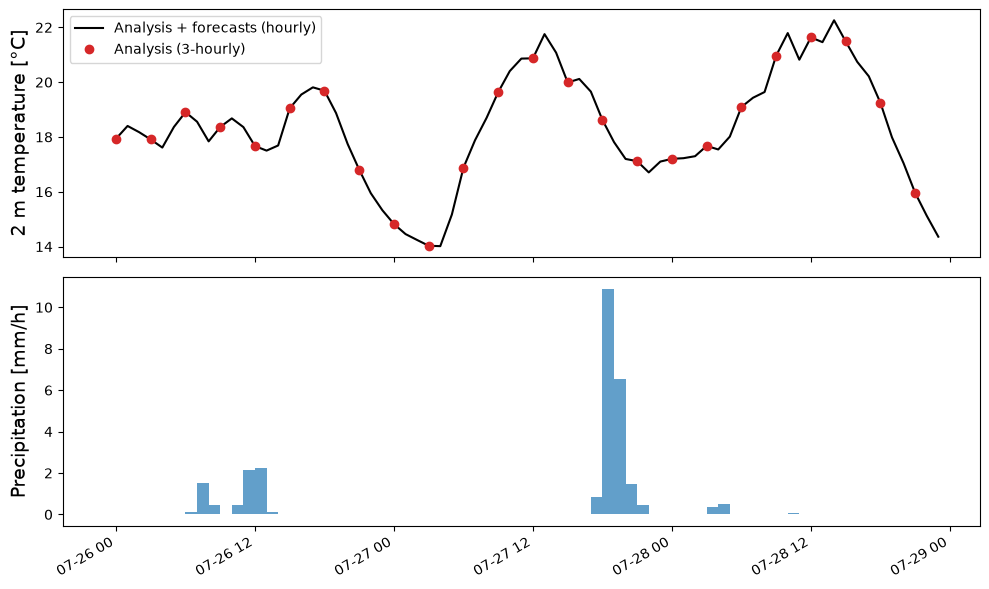

In [10]:
fig, (ax_t, ax_tp) = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True, tight_layout=True
)

ax_t.plot(
    ds_pt.time,
    ds_pt.t2m - 273.15,
    color="k",
    label="Analysis + forecasts (hourly)",
)
ax_t.plot(
    ana_pt.time,
    ana_pt - 273.15,
    "o",
    color="C3",
    label="Analysis (3-hourly)",
)
ax_t.set_ylabel("2 m temperature [°C]", fontsize=14)
ax_t.legend()

ax_tp.bar(
    ds_pt.time - pd.Timedelta("30min"),
    ds_pt.tp_accum_past_hr,
    width=pd.Timedelta("1h"),
    edgecolor=None,
    alpha=0.7,
)
ax_tp.set_ylabel("Precipitation [mm/h]", fontsize=14)
fig.autofmt_xdate()

## Pressure and height levels

The pressure and height level datasets contain the same variables in the analysis and the forecasts, so for these we only need the first of the two steps above.
We wrap the steps in a function, so it can be used for all three level types:

In [11]:
def combine_analysis_forecast(ds_ana, ds_fc):
    """Combine analysis and 3-hourly forecasts along one hourly time axis."""
    common_vars = sorted(set(ds_ana.data_vars) & set(ds_fc.data_vars))
    fc_only_vars = sorted(set(ds_fc.data_vars) - set(ds_ana.data_vars))

    # Use the analysis where available, and the 1 and 2 hour forecasts between
    ds_fc_valid = make_valid_time_dimension(
        ds_fc[common_vars].sel(forecast_period=lead_times)
    )
    ds = xr.concat(
        [ds_ana, ds_fc_valid],
        dim="time",
        combine_attrs="drop_conflicts",
        join="outer",
        data_vars="minimal",
        coords=["time"],
    ).sortby("time")

    # Variables only in the forecasts keep all lead times
    if fc_only_vars:
        ds_fc_only = make_valid_time_dimension(ds_fc[fc_only_vars])
        ds_fc_only = ds_fc_only.sel(time=slice(None, ds.time.values[-1]))
        ds = xr.merge([ds, ds_fc_only], join="outer", compat="override")

    return ds

In [12]:
ds_pl = combine_analysis_forecast(
    open_danra("pressure_levels_analysis"),
    open_danra("pressure_levels_forecast_PT3H"),
)
ds_hl = combine_analysis_forecast(
    open_danra("height_levels_analysis"),
    open_danra("height_levels_forecast_PT3H"),
)

Finally, all three level types can be merged into one dataset.
Some variable names, such as `t`, `r`, `u` and `v`, are used in both the pressure and height level datasets, so we prefix them with `pl_` and `hl_` to keep them apart.
The `danra_projection` variable, which describes the map projection, is the same in all datasets, so we only keep the one from the single levels:

In [13]:
ds_pl = ds_pl.drop_vars("danra_projection")
ds_pl = ds_pl.rename({var: "pl_" + var for var in ds_pl.data_vars})

ds_hl = ds_hl.drop_vars("danra_projection")
ds_hl = ds_hl.rename({var: "hl_" + var for var in ds_hl.data_vars})

ds = xr.merge([ds_sl, ds_pl, ds_hl], join="outer", compat="override")
ds

<xarray.Dataset> Size: 234TB
Dimensions:                   (time: 292200, x: 789, y: 589, pressure: 14,
                               height: 9)
Coordinates:
  * time                      (time) datetime64[ns] 2MB 1990-09-01 ... 2023-1...
  * x                         (x) float64 6kB -1.999e+06 ... -2.925e+04
    lat                       (y, x) float64 4MB 47.65 47.66 ... 64.42 64.42
    lon                       (y, x) float64 4MB -2.094 -2.064 ... 24.34 24.4
  * y                         (y) float64 5kB -6.095e+05 -6.07e+05 ... 8.605e+05
  * pressure                  (pressure) int64 112B 1000 950 925 ... 250 200 100
  * height                    (height) int64 72B 30 50 75 100 ... 250 300 500
Data variables: (12/82)
    albedo                    (time, y, x) float64 1TB dask.array<chunksize=(383, 295, 263), meta=np.ndarray>
    cape_column               (time, y, x) float64 1TB dask.array<chunksize=(383, 295, 263), meta=np.ndarray>
    cb_column                 (time, y, x) float64 1TB dask.array<chunksize=(383, 295, 263), meta=np.ndarray>
    ct_column                 (time, y, x) float64 1TB dask.array<chunksize=(383, 295, 263), meta=np.ndarray>
    danra_projection          float64 8B nan
    fog                       (time, y, x) float64 1TB dask.array<chunksize=(383, 295, 263), meta=np.ndarray>
    ...                        ...
    pl_v                      (time, pressure, y, x) float64 15TB dask.array<chunksize=(383, 1, 295, 263), meta=np.ndarray>
    pl_z                      (time, pressure, y, x) float64 15TB dask.array<chunksize=(383, 1, 295, 263), meta=np.ndarray>
    hl_r                      (time, height, y, x) float64 10TB dask.array<chunksize=(383, 1, 295, 263), meta=np.ndarray>
    hl_t                      (time, height, y, x) float64 10TB dask.array<chunksize=(383, 1, 295, 263), meta=np.ndarray>
    hl_u                      (time, height, y, x) float64 10TB dask.array<chunksize=(383, 1, 295, 263), meta=np.ndarray>
    hl_v                      (time, height, y, x) float64 10TB dask.array<chunksize=(383, 1, 295, 263), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.8
    contact:      Leif Denby <lcd@dmi.dk>, Danish Meteorological Institute
    description:  All prognostic variables for 1990-09-01T00:00Z to 2024-01-0...
    license:      CC-BY-4.0: https://creativecommons.org/licenses/by/4.0/

## Using the 18-hourly forecasts

The 18-hourly forecasts are started every 12 hours, at 00 UTC and 12 UTC, so consecutive forecasts overlap by 6 hours.
To get one value for every hour, we can use the 1 to 12 hour lead times of each forecast.
Since the analysis is only available every 3 hours, these forecasts are not combined with the analysis: every hour comes from a forecast, and the hours at 00 UTC and 12 UTC come from the 12 hour lead time of the previous forecast.
Apart from the selection of lead times, the procedure is the same as above:

In [14]:
fc18_sl = open_danra("single_levels_forecast_PT18H")

lead_times_18h = pd.timedelta_range("1h", "12h", freq="1h")
ds18_sl = make_valid_time_dimension(
    fc18_sl.sel(forecast_period=lead_times_18h)
)

We can now compare the hourly precipitation from the two sets of forecasts for the same period as above:

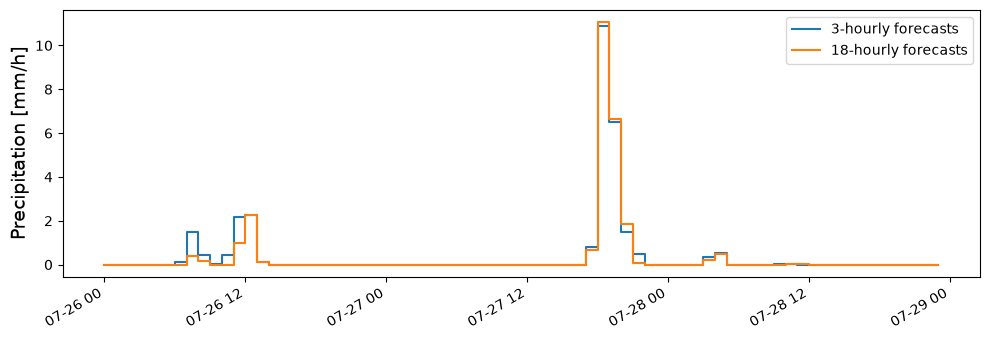

In [15]:
ds18_pt = ds18_sl.tp_accum_past_hr.isel(y=iy, x=ix).sel(time=period).compute()

fig, ax = plt.subplots(1, 1, figsize=(10, 3.5), tight_layout=True)
ax.step(
    ds_pt.time,
    ds_pt.tp_accum_past_hr,
    where="pre",
    label="3-hourly forecasts",
)
ax.step(ds18_pt.time, ds18_pt, where="pre", label="18-hourly forecasts")
ax.set_ylabel("Precipitation [mm/h]", fontsize=14)
ax.legend()
fig.autofmt_xdate()